# Linking observations

So far, we linked *features* of different modalities, e.g. peptides to proteins. `mulink` can also link *observations* of different modalities, for example single cells segmented from an image to the pooled samples that were sent for RNA sequencing.

Which axis is linked follows from the [shared axis of the MuData object](https://mudata.readthedocs.io/stable/notebooks/axes.html#axes-in-mudata):

- `axis=0` (default): observations are shared, links connect **variables** and are stored in `mdata.varp`.
- `axis=1`: variables are shared, links connect **observations** and are stored in `mdata.obsp`.

All `mulink` functions derive the axis from the MuData object, so you do not need to pass it explicitly.

In [1]:
import anndata as ad
import mudata as md
import networkx as nx
import numpy as np
import pandas as pd

import mulink  # noqa: F401 - registers the `.link` namespace on mudata objects

rng = np.random.default_rng(seed=42)

## Data

We simulate two modalities:

- `image`: five segmented cells, each described by three image features.
- `rna`: three pooled samples. Each sample contains the RNA of one or two of the imaged cells.

In [2]:
image = ad.AnnData(
    X=rng.random(size=(5, 3)),
    obs=pd.DataFrame(index=["cell-0", "cell-1", "cell-2", "cell-3", "cell-4"]),
    var=pd.DataFrame(index=["dim-0", "dim-1", "dim-2"]),
)

rna = ad.AnnData(
    X=rng.random(size=(3, 6)),
    obs=pd.DataFrame(index=["pool-0", "pool-1", "pool-2"]),
    var=pd.DataFrame(index=[f"gene-{idx}" for idx in range(6)]),
)

The modalities describe different observations, so we concatenate them along the observation axis with `axis=1`.

In [3]:
mdata = md.MuData({"image": image, "rna": rna}, axis=1)
mdata

MuData object with n_obs × n_vars = 8 × 9 (shared var) 
  2 modalities
    image:	5 × 3
      layers:	None
    rna:	3 × 6
      layers:	None

## Adding a link

The link is a directed graph between the observations of the MuData object. Here, every cell points to the pool that contains its RNA. The adjacency matrix has to follow the order of `mdata.obs_names`.

In [4]:
cell_to_pool = pd.DataFrame(
    {
        "image": ["cell-0", "cell-1", "cell-2", "cell-3", "cell-4"],
        "rna": ["pool-0", "pool-0", "pool-1", "pool-1", "pool-2"],
    }
)

dag = nx.from_pandas_edgelist(cell_to_pool, source="image", target="rna", create_using=nx.DiGraph)
adjacency_matrix = nx.adjacency_matrix(dag, nodelist=mdata.obs_names)

mdata.link.add_link(adjacency_matrix, key="pooled_in", semantics="pooled_in")

As `mdata.axis == 1`, the link is stored in `mdata.obsp` and indexed by the observation names.

In [5]:
mdata.obsp

PairwiseArrays with keys: 'pooled_in'

In [6]:
mdata.link.link(key="pooled_in")

,cell-0,cell-1,cell-2,cell-3,cell-4,pool-0,pool-1,pool-2
cell-0,0,0,0,0,0,1,0,0
cell-1,0,0,0,0,0,1,0,0
cell-2,0,0,0,0,0,0,1,0
cell-3,0,0,0,0,0,0,1,0
cell-4,0,0,0,0,0,0,0,1
pool-0,0,0,0,0,0,0,0,0
pool-1,0,0,0,0,0,0,0,0
pool-2,0,0,0,0,0,0,0,0


## Plotting

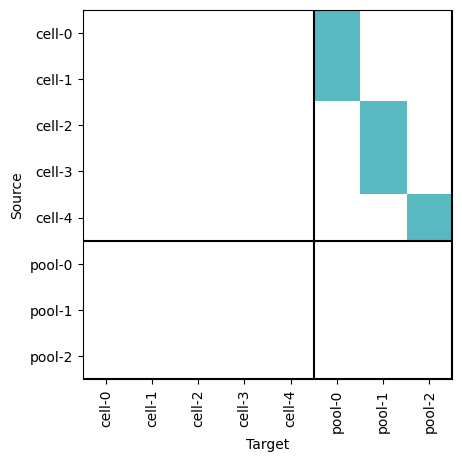

In [7]:
mdata.link.pl.adjacency_matrix(key="pooled_in", label=True, mod_limits=True);

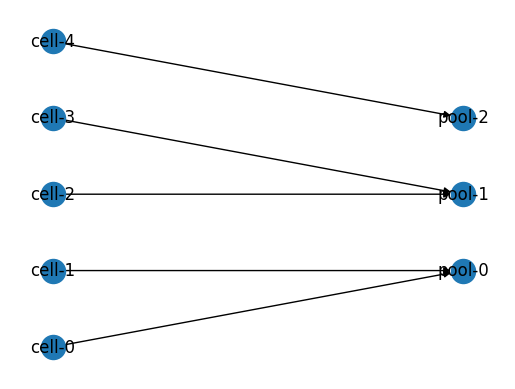

In [8]:
mdata.link.pl.graph(key="pooled_in", with_labels=True)

## Querying

Queries return a subset of the MuData object along the linked axis. For example, we can retrieve the pool that contains the RNA of `cell-4`. All variables are retained.

In [9]:
subset = mdata.link.query.descendants("cell-4", key="pooled_in")
subset

View of MuData object with n_obs × n_vars = 2 × 9 (shared var) 
  uns:	'mulink'
  obsp:	'pooled_in'
  2 modalities
    image:	1 × 3
      layers:	None
    rna:	1 × 6
      layers:	None

In [10]:
subset.mod["rna"].to_df()

,gene-0,gene-1,gene-2,gene-3,gene-4,gene-5
pool-2,0.043804,0.154289,0.683049,0.744762,0.96751,0.325825


Conversely, we can retrieve all cells that contribute to `pool-0` and restrict the result to the `image` modality.

In [11]:
mdata.link.query.ancestors("pool-0", key="pooled_in", include_mods="image").mod["image"].obs_names

Index(['cell-0', 'cell-1'], dtype='object')